# Week 5 (10/1/2026): Supervised Categorization, Part 2

This is last week's worked notebook, unchanged up to the ROC curve: load and merge the two Bloomberg files, build the AI-stock target, split, then Gaussian Naive Bayes, LDA, logistic regression, precision, recall and AUC. **Run it top to bottom first**; it needs the two Bloomberg files below. These are licensed Bloomberg PORT exports and are not included in this repository; the README describes the columns so you can follow along with your own cross-section of stocks.

* `20260917_BLG_Port.xlsx`: valuation ratios, sector, market cap, returns, and factor exposures from Bloomberg's legacy US equity risk model
* `20260917_BLG_Port_2.xlsx`: buybacks, shares outstanding, capex estimates, quality scores, default risk, and factor exposures from **MAC3**, Bloomberg's current multi-asset risk model (17 style factors)

**New this week:** the sector column joins the features through one-hot encoding, so every model below uses 17 MAC3 factors plus the sector dummies. Then, at the end, the same classification problem with a neural network in PyTorch. Three questions: what the learning rate does, what the Adam optimizer buys you, and whether regularization (dropout, weight decay) is useful here or not.

In [ ]:
# Data download removed: the two Bloomberg PORT exports are licensed and not redistributed (see README).
# Place 20260917_BLG_Port.xlsx and 20260917_BLG_Port_2.xlsx in the working directory.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df1 = pd.read_excel("20260917_BLG_Port.xlsx", skiprows=2)
df2 = pd.read_excel("20260917_BLG_Port_2.xlsx", skiprows=2)
df1.shape, df2.shape

((1603, 41), (1603, 40))

## Clean the junk rows

Bloomberg said 1,600 securities. We have 1,603 rows. **Where are the extra three?**

Last week's trick: rows that are not real stocks have no Short Name. Filter with `isna` / `notna`, never with `== None`.

In [4]:
set(df1.columns).intersection(set(df2.columns))

{'Equity Traded Val:D-1',
 'Rank(Equity Traded Val 1 Day ago)',
 'Short Name',
 'Ticker',
 'Ticker.1'}

In [5]:
# df1["Short Name"]==np.nan --- never do this

In [6]:
df1["Short Name"].isna()

0        True
1       False
2       False
3       False
4       False
        ...  
1598    False
1599    False
1600    False
1601     True
1602     True
Name: Short Name, Length: 1603, dtype: bool

In [7]:
df1[df1["Short Name"].isna()][["Ticker"]]

In [8]:
# df1[df1["Short Name"].notna()][["Ticker"]]
df1[~ df1["Short Name"].isna()][["Ticker"]]

One grouping row, one blank row, and the full Bloomberg legal disclaimer sitting in the last row. Real exports have footers. If you skip this check, the disclaimer becomes a data point.

In [9]:
df1 = df1[df1["Short Name"].notna()]
df2 = df2[df2["Short Name"].notna()]
df1.shape, df2.shape

((1600, 41), (1600, 40))

## Merge the two files

This is the first real step today. Two tables, one universe of stocks; we want one wide table.

Before any merge, pick the join key and **prove it is unique on both sides**. Candidates here: `Ticker`, which both files carry, or `CUSIP`, the official security identifier, which looks like the safer key. **Is it?**

In [10]:
'CUSIP' in df1.columns, 'CUSIP' in df2.columns
# Even though CUSIP is a unique identifier, you cannot use it to join because it's only in one of the two data frames.

(True, False)

In [11]:
print("df1 duplicate Ticker:", df1["Ticker"].duplicated().sum())
print("df2 duplicate Ticker:", df2["Ticker"].duplicated().sum())

df1 duplicate Ticker: 0
df2 duplicate Ticker: 0


The official identifier fails on both counts: 143 duplicate values in file 1 (144 CUSIPs are simply missing, and every missing value collides with every other missing value), and file 2 does not carry the column at all. The humble ticker is unique on both sides. The lesson: never assume a key is clean, check it.

Next, a dry run. An outer merge with `indicator=True` tells us who matches, who is only in the left file, and who is only in the right file, before we commit.

In [12]:
probe = df1.merge(df2, on="Ticker", how="outer", indicator=True, suffixes=("_f1", "_f2"))
probe["_merge"].value_counts()

_merge
both          1600
left_only        0
right_only       0
Name: count, dtype: int64

Every row matches. Now the real merge. `validate="one_to_one"` makes pandas throw an error if either side has duplicate keys, so silent row explosions cannot happen.

Last week's reflection question: **what do you check immediately after every merge?**

1. Row counts before and after
2. Duplicate keys (the `validate` argument does this for us)
3. The indicator dry run above
4. A column that exists in both files should agree between the two sides

In [13]:
df = df1.merge(df2, on="Ticker", how="inner", suffixes=("_f1", "_f2"), validate="one_to_one")
print("rows before:", len(df1), "and", len(df2), "| rows after:", len(df))

rows before: 1600 and 1600 | rows after: 1600


In [14]:
# check 4: both files carry yesterday's traded value; the two copies must agree
a = df["Equity Traded Val:D-1_f1"]
b = df["Equity Traded Val:D-1_f2"]
print("max abs difference:", (a - b).abs().max())

max abs difference: 0.0


In [15]:
# So DF1 had 41 columns, and DF2 has 40 columns. And then when you merge them, you get 80 columns in total.
df.shape, df1.shape, df2.shape

((1600, 80), (1600, 41), (1600, 40))

# Set an Index


In [16]:
def getTicker(s):
  return s.split()[0]

df.Ticker.map(getTicker)

In [17]:
df.Ticker.map(lambda s: s.split()[0])

In [18]:
df.Ticker.str.split(expand=True)[0]


In [19]:
df.Ticker=df.Ticker.map(lambda s: s.split()[0])

In [20]:
df = df.set_index('Ticker')

# Rename Columns


In [21]:
column_mapping = {
    "Short Name_f1": "short_name_1",
    "Ticker.1_f1": "ticker_1",
    "PORT US Prof Fact Exp:D-1": "port_us_profitability",
    "PORT US Vol Fact Exp:D-1": "port_us_volatility",
    "PORT US Lev Fact Exp:D-1": "port_us_leverage",
    "PORT US Mom Fact Exp:D-1": "port_us_momentum",
    "PORT US Val Fact Exp:D-1": "port_us_value",
    "PORT US Gr Fact Exp:D-1": "port_us_growth",
    "PORT US Dvd Yld Fact Exp:D-1": "port_us_dividend_yield",
    "PORT US Earn Var Fact Exp:D-1": "port_us_earnings_variability",
    "P/S": "price_to_sales",
    "BEst P/S BF12M": "est_price_to_sales_fwd12m",
    "P/B": "price_to_book",
    "BEst P/B BF12M": "est_price_to_book_fwd12m",
    "P/E": "price_to_earnings",
    "BEst P/E BF12M": "est_price_to_earnings_fwd12m",
    "ROE LF": "roe_last_fiscal",
    "GICS SubInd": "gics_sub_industry",
    "GICS Sector": "gics_sector",
    "GICS Ind Name": "gics_industry_name",
    "GICS SubInd Name": "gics_sub_industry_name",
    "ESG Disclosure Score (Latest Available)": "esg_disclosure_score",
    "Beta:Y-1": "beta_1y",
    "Total Return:Y-1": "total_return_1y",
    "Number of Employees:Y": "num_employees",
    "Number of Employees:Y-5": "num_employees_5y_ago",
    "Market Cap": "market_cap",
    "Total Return:M-3": "total_return_3m",
    "Gr PoP of Tot Debt:Q:Q[currency=LCL], -12)": "total_debt_growth_qoq_12m",
    "Insider Sells Volume 1 Year:Y-1": "insider_sells_volume_1y",
    "FCF Yld": "fcf_yield",
    "FCF Yld:Q-12": "fcf_yield_q_12m",
    "Net Fixed Asset Turnover LF": "net_fixed_asset_turnover_lf",
    "PORT US Sz Fact Exp:D-1": "port_us_size",
    "Gr PoP of Net Fixed Asset Turnover:Y:Y, -5)": "net_fixed_asset_turnover_growth_5y",
    "Equity Traded Val:D-1_f1": "equity_traded_value_1d",
    "Rank(Equity Traded Val 1 Day ago)_f1": "equity_traded_value_rank_1d",
    "CUSIP": "cusip",
    "FCF Yld:Y": "fcf_yield_y",
    "FCF Yld:Y-1": "fcf_yield_y_1",
    "Short Name_f2": "short_name_2",
    "Equity Traded Val:D-1_f2": "equity_traded_value_1d_2",
    "Rank(Equity Traded Val 1 Day ago)_f2": "equity_traded_value_rank_1d_2",
    "Ticker.1_f2": "ticker_2",
    "Avg Px Pd Repurch LF": "avg_price_paid_repurchase_lf",
    "Val Sh Repurch fr Repurch Prog:Y": "value_shares_repurchased_y",
    "Val Sh Repurch fr Repurch Prog:Y-1": "value_shares_repurchased_y_1",
    "Shares Out:Y": "shares_outstanding",
    "Shares Out:Y-1": "shares_outstanding_y_1",
    "BEst CAPEX BF12M": "est_capex_fwd12m",
    "BEst CAPEX:CQ-4 BF12M": "est_capex_cq4_fwd12m",
    "Energy Intensity per Sales (Latest Available) (BLOOMBERG L.P.)": "energy_intensity_per_sales",
    "Engy Intens/Empl:Y": "energy_intensity_per_employee",
    "Engy Intens/EBITDA:Y": "energy_intensity_per_ebitda",
    "BI STOX Quality (BLOOMBERG L.P.)": "bi_stox_quality",
    "BI STOX Leverage (BLOOMBERG L.P.)": "bi_stox_leverage",
    "BI STOX Low Volatility (BLOOMBERG L.P.)": "bi_stox_low_volatility",
    "BI STOX Profitability (BLOOMBERG L.P.)": "bi_stox_profitability",
    "BI STOX Multi-Factor Score (BLOOMBERG L.P.)": "bi_stox_multi_factor_score",
    "Bloomberg Issuer Likelihood of Default (Adjusted)": "bbg_issuer_default_likelihood",
    "Bloomberg Issuer Default Risk Implied CDS Spread (Adjusted)": "bbg_issuer_default_risk_cds",
    "BI STOX Momentum (BLOOMBERG L.P.)": "bi_stox_momentum",
    "PORT MAC3 Lqdty Factor Exp:D-1": "port_mac3_liquidity",
    "PORT MAC3 Dvd Yld Factor Exp:D-1": "port_mac3_dividend_yield",
    "PORT MAC3 Value Factor Exp:D-1": "port_mac3_value",
    "PORT MAC3 Beta Factor Exp:D-1": "port_mac3_beta",
    "PORT MAC3 Prof Factor Exp:D-1": "port_mac3_profitability",
    "PORT MAC3 Vol Factor Exp:D-1": "port_mac3_volatility",
    "PORT MAC3 Residl Vol Factor Exp:D-1": "port_mac3_residual_volatility",
    "PORT MAC3 Var Factor Exp:D-1": "port_mac3_variability",
    "PORT MAC3 Ern Yld Factor Exp:D-1": "port_mac3_earnings_yield",
    "PORT MAC3 Gwth Factor Exp:D-1": "port_mac3_growth",
    "PORT MAC3 Qual Factor Exp:D-1": "port_mac3_quality",
    "PORT MAC3 LT Rev Factor Exp:D-1": "port_mac3_long_term_reversal",
    "PORT MAC3 Size Factor Exp:D-1": "port_mac3_size",
    "PORT MAC3 Mom Factor Exp:D-1": "port_mac3_momentum",
    "PORT MAC3 Lvrg Factor Exp:D-1": "port_mac3_leverage",
    "PORT MAC3 Mid Cap Factor Exp:D-1": "port_mac3_mid_cap",
    "PORT MAC3 Valtn Factor Exp:D-1": "port_mac3_valuation",
}

In [22]:
df = df.rename(columns=column_mapping)

# Categorization

* Requires a target variable
* ML Algo assigns a class





## Create Target Variable

* Tgt Variable:
  * 0 if stock is not in our AI short list
  * 1 if stock is in our AI short list

* Binary classification problem.

In [23]:
ai_tickers = [
    # US-listed tickers
    "AAOI", "AAPL", "ALAB", "AMAT", "AMD", "AMZN", "ANET", "ARM",
    "ASML", "AVGO", "BABA", "BIDU", "CBRS", "COHR", "CRDO", "CRM",
    "CRWD", "CRWV", "CSCO", "DDOG", "DELL", "ETN", "FLEX", "GEV",
    "GOOGL", "HUT", "IBM", "INTC", "IREN", "KI5", "LITE", "LRCX",
    "LSCC", "MDB", "META", "MRVL", "MSFT", "MTSI", "MU", "NBIS",
    "NEE", "NET", "NFLX", "NOW", "NTNX", "NVDA", "OKLO", "ORCL",
    "PANW", "PLTR", "QCOM", "RBLX", "RIOT", "SAP", "SHOP", "SKM",
    "SMCI", "SNDK", "SNOW", "SPCX", "SSNLF", "TER", "TSEM", "TSLA",
    "TSM", "VRT", "WDC", "YNDX", "ZS",
    # Non-US listed tickers (exchange-local symbols)
    "000660", "005930", "0700", "2308", "2330", "2345", "2360",
    "2383", "2454", "2513", "3017", "3037", "3711", "402340",
    "6669", "6857", "6976", "8035", "9984"
]

In [24]:
df.index.isin(ai_tickers).sum() # Imbalanced Class


65

In [25]:
# df.index.isin(ai_tickers).astype(int)
df.index.isin(ai_tickers)+0

array([0, 0, 0, ..., 0, 0, 0])

In [26]:
df['TgtVariable'] = df.index.isin(ai_tickers)+0

## One-hot encoding the sector

Sector is text: Information Technology, Health Care, Energy, and eight more. Models need numbers. **Why not just number the sectors 1 to 11?** Because then the model would read Utilities as eleven times Communication Services, and Energy as sitting halfway between two other sectors. The numbers would invent an order and a distance that do not exist.

One-hot encoding gives each sector its own 0/1 column: a stock gets a 1 in its own sector's column and 0 everywhere else. We keep 10 of the 11 columns (`drop_first=True`). The 11 columns would always add up to exactly 1, which is the same information as the intercept. That redundancy is called the dummy variable trap: it makes LDA's covariance matrix singular and leaves logistic regression's coefficients without a unique answer. The dropped sector, Communication Services, becomes the baseline the others are measured against.

There is nothing to fit here, so it is safe to do before the split.

In [27]:
df['gics_sector'].value_counts()

gics_sector
Industrials               280
Information Technology    254
Financials                248
Health Care               228
Consumer Discretionary    195
Energy                    108
Materials                  97
Consumer Staples           66
Communication Services     64
Utilities                  51
Real Estate                 9
Name: count, dtype: int64

In [28]:
sector_dummies = pd.get_dummies(df['gics_sector'], prefix='sector', drop_first=True, dtype=int)
sector_dummies.columns = sector_dummies.columns.str.lower().str.replace(' ', '_')
df = df.join(sector_dummies)
sector_names = list(sector_dummies.columns)
print(len(sector_names), 'sector columns:', sector_names)
df[['gics_sector'] + sector_names].head()

10 sector columns: ['sector_consumer_discretionary', 'sector_consumer_staples', 'sector_energy', 'sector_financials', 'sector_health_care', 'sector_industrials', 'sector_information_technology', 'sector_materials', 'sector_real_estate', 'sector_utilities']


Is sector worth adding? Check the AI rate inside each sector before you model anything.

In [29]:
df.groupby('gics_sector')['TgtVariable'].agg(['count', 'sum', 'mean']).sort_values('mean', ascending=False).round(3)

,count,sum,mean
gics_sector,,,
Information Technology,254,51,0.201
Communication Services,64,6,0.094
Utilities,51,2,0.039
Consumer Discretionary,195,3,0.015
Industrials,280,3,0.011
Consumer Staples,66,0,0.000
Energy,108,0,0.000
Financials,248,0,0.000
Health Care,228,0,0.000


**Reading it.** Information Technology holds 51 of the 65 AI stocks, and one IT stock in five is on the list. Communication Services comes next at 9 percent (Alphabet, Meta, Netflix and three more). Six sectors have no AI stocks at all. No MAC3 factor carries this information: the factors describe how a stock behaves (its beta, momentum, valuation), and sector describes what the company does.

Two cautions. First, our label is a hand-made list, and whoever wrote it was thinking in sectors, so part of what a model learns here is the list-maker's habits. Second, those six empty sectors separate perfectly: no stock in them is AI. An unpenalized logistic regression would push their coefficients toward minus infinity chasing that. scikit-learn's default penalty (`C=1`) keeps them finite, which is regularization doing its job before we have even named it.


## Train-Test Split?

The train-test split approach addresses fundamental limitations of in-sample analysis:
1. Tests generalization ability
2. Reduces overfitting
3. Provides realistic performance estimates
4. Validates model stability

This shift reflects a broader change in statistical practice:
- From: "Is this relationship significant?"
- To: "Can this model make reliable predictions?"

In [30]:
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42) # Probably wrong

In [31]:
train_df['TgtVariable'].sum()/len(train_df), test_df['TgtVariable'].sum()/len(test_df)

(0.03984375, 0.04375)

Stratified Sampling for class-imbalance

In [32]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=5, stratify=df['TgtVariable'])
train_df['TgtVariable'].sum()/len(train_df), test_df['TgtVariable'].sum()/len(test_df)

(0.040625, 0.040625)

# Feature Selection

* All 17 MAC3 factor exposures, plus the 10 sector dummies from the one-hot step: 27 features.

In [33]:
mac3_names = list(df.filter(like='_mac3_').columns)
fnames = mac3_names + sector_names
print(len(fnames), 'features:', len(mac3_names), 'MAC3 factors +', len(sector_names), 'sector dummies')

27 features: 17 MAC3 factors + 10 sector dummies


# Gaussian Naive Bayes

- We start with the Bayes Model from the textbook - Ch 4.3 Equation 4.7.
- The conditional probability of class k given x is proportional to:
  - The likelihood of observing x given class k, denoted as fₖ(x), multiplied by the prior probability of class k, denoted as πₖ.
  - In other words, we are more convinced that G = k given X = x if the likelihood of the evidence fₖ(x) is high and the class k is common (i.e., has a high prior probability πₖ).

$$\Pr(G=k \mid X=x) = \frac{f_k(x)\,\pi_k}{\sum_{\ell=1}^{K} f_\ell(x)\,\pi_\ell}$$

*(Elements of Statistical Learning, Eq. 4.7)*

- Estimating the prior probability πₖ is straightforward if we have a random sample from the population: we simply compute the fraction of the training observations that belong to the k-th class. However, estimating the likelihood function fₖ(x) is much more challenging. To estimate fₖ(x), we typically need to make simplifying assumptions.

- The Naive Bayes model assumes that, for every class, the features x are conditionally independent given the class.
- Gaussian Naive Bayes further assumes that the likelihood function fₖ(x) follows a normal (Gaussian) distribution:
  * fₖ(x) = (1 / √(2πσₖ²)) * exp(-(x - μₖ)² / (2σₖ²)),
  * where μₖ and σₖ² are the mean and variance of x for class k.

- These assumptions introduce bias by oversimplifying the true data distribution, but they significantly reduce variance by making the model less sensitive to small fluctuations in the training data. This often leads to better generalization performance, especially in high-dimensional settings.

- For further reading, refer to the ElemStatLearn textbook:
- Section 6.6.3: The Naive Bayes Classifier.

![](https://iq.opengenus.org/content/images/2020/02/Illustration-of-how-a-Gaussian-Naive-Bayes-GNB-classifier-works-For-each-data-point.png)


<Axes: ylabel='Density'>

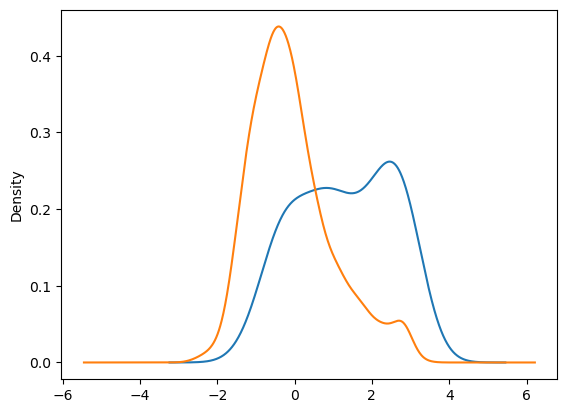

In [34]:
df.loc[df.TgtVariable==1,'port_mac3_beta'].plot(kind='kde')
df.loc[df.TgtVariable==0,'port_mac3_beta'].plot(kind='kde')

In [35]:
from sklearn.naive_bayes import GaussianNB #In this case, ML = GaussianNB
clf = GaussianNB()
clf.fit(X=train_df[fnames], y=train_df['TgtVariable'])


,priors,None
,var_smoothing,1e-09


In [36]:
ytrain_pred = clf.predict(train_df[fnames])
ytrain_pred

array([1, 1, 0, ..., 1, 0, 0])

In [37]:
ytrain=train_df['TgtVariable'].values
ytrain

array([0, 0, 0, ..., 0, 0, 0])

In [38]:
# print classification report  on training set
from sklearn.metrics import classification_report
print(classification_report(train_df['TgtVariable'], ytrain_pred))


              precision    recall  f1-score   support

           0       1.00      0.57      0.72      1228
           1       0.09      1.00      0.16        52

    accuracy                           0.58      1280
   macro avg       0.54      0.78      0.44      1280
weighted avg       0.96      0.58      0.70      1280



* **precision**: when the model predicts positive, what percent are actually positive
* **recall**: of the actual positives, what percent the model found
* **f1**: the harmonic mean of precision and recall, 2PR / (P + R). It punishes whichever of the two is weaker, which is why 25% precision and 85% recall give an F1 of 39%, not the simple average of 55%.

In [39]:
pos = (ytrain==1)
neg = (ytrain==0)

tp = (pos & (ytrain == ytrain_pred)).sum()
tp_rate = tp/pos.sum()
tn = (neg & (ytrain == ytrain_pred)).sum()
tn_rate = tn/neg.sum()
fn = (pos & (ytrain_pred==0)).sum()
fp = (neg & (ytrain_pred==1)).sum()

print(f'{tp=} {tp_rate=:.2%}')
print(f'{tn=} {tn_rate=:.2%}')
print(f'{fn=} {fp=}')
recall = tp/(tp+fn)
precision = tp/(tp+fp)
f1 = 2*recall*precision/(recall+precision)
print(f'{recall=:.2%}')
print(f'{precision=:.2%}')
print(f'{f1=:.2%}')
#

tp=52 tp_rate=100.00%
tn=695 tn_rate=56.60%
fn=0 fp=533
recall=100.00%
precision=8.89%
f1=16.33%


In [40]:
# Now on the test set
ytest_pred = clf.predict(test_df[fnames])
ytest=test_df['TgtVariable'].values
print(classification_report(test_df['TgtVariable'], ytest_pred))

              precision    recall  f1-score   support

           0       1.00      0.56      0.72       307
           1       0.09      1.00      0.16        13

    accuracy                           0.58       320
   macro avg       0.54      0.78      0.44       320
weighted avg       0.96      0.58      0.70       320



**What happened to Naive Bayes?** With the sector dummies added, it calls 533 of the 1,228 non-AI training stocks AI: recall 100 percent, precision 9 percent, accuracy 58 percent. The model broke because one of its assumptions broke.

Gaussian Naive Bayes fits a bell curve to every feature within each class. A 0/1 column is not a bell curve. Worse, in the AI class the six sectors with no AI stocks are 0 for every single stock, so their fitted bell curve has almost no width, a spike that assigns an enormous likelihood to the value 0. Any stock outside those six sectors collects six enormous votes for "AI" before the MAC3 factors get a say. The fix is a model whose assumptions match the data: Bernoulli or categorical Naive Bayes for 0/1 columns, or keep Gaussian Naive Bayes on the continuous factors only. Keep an eye on its test AUC in the final table.

# Linear Discriminant Analysis (LDA)

- We start with the Bayes Model from the textbook - Ch 4.3 Equation 4.7.
- The conditional probability of class k given x is proportional to:
  - The class k marginal density of x multiplied by the prior probability of class k.
  - In other words, we are convinced that G = k given X = x if the likelihood of the evidence is high and the class k is common (i.e., has a high prior probability).

$$\Pr(G=k \mid X=x) = \frac{f_k(x)\,\pi_k}{\sum_{\ell=1}^{K} f_\ell(x)\,\pi_\ell}$$

*(Elements of Statistical Learning, Eq. 4.7)*

- For further reading, refer to the ElemStatLearn textbook:
  - Section 4.3: Linear Discriminant Analysis.

---

## Assumptions of LDA

- LDA is derived under the following assumptions:
  1. **Class marginal densities are Gaussian**:
     - Similar to Gaussian Naive Bayes (GNB), LDA assumes that the class-conditional densities follow a Gaussian (normal) distribution.
  2. **Inputs to the class marginal densities can be dependent**:
     - Unlike GNB, LDA allows for dependencies between the input features. This means the covariance matrix of the class-conditional densities is not diagonal.
  3. **All classes share the same covariance matrix**:
     - LDA assumes that the covariance matrix is the same for all classes. This is a key difference from GNB, where each class can have its own covariance matrix.

---

## Comparison of LDA and GNB

- Both LDA and GNB start from the same Bayes model but deviate in their assumptions:
  - **Gaussian Naive Bayes (GNB)**:
    - Allows the marginal densities of different classes to have different variances (i.e., each class has its own covariance matrix).
    - Assumes that the input features are independent (i.e., the covariance matrix is diagonal).
  - **Linear Discriminant Analysis (LDA)**:
    - Allows the input features to be dependent (i.e., the covariance matrix is not diagonal).
    - Requires that all classes share the same covariance matrix.

- **Neither model is a subset of the other**:
  - GNB and LDA make different tradeoffs between flexibility and simplicity. GNB is more restrictive in assuming independence, while LDA is more restrictive in assuming a shared covariance matrix.

## Math

The class marginal density is assumed to be that of a multivariate Guassian is given by

![](https://wikimedia.org/api/rest_v1/media/math/render/svg/c66e6f6abd66698181e114a4b00da97446efd3c4)

To determine which class is more likely, the likelihood ratio would be compared against a certain threshold t.

![](https://wikimedia.org/api/rest_v1/media/math/render/svg/8a6d6a1a61981e64212b83288b205d311f13b80a)

Taking log, this becomes Quadratic Discriminant Analysis.

![](https://wikimedia.org/api/rest_v1/media/math/render/svg/1b9954e129b47bb7696b199b73c14bcc849d4cb6)

LDA assumes equal covariances. Terms cancel out.

![](https://wikimedia.org/api/rest_v1/media/math/render/svg/4b58cdf092dbf241d217dbca9b1e16a6335c7b0f)

![](https://wikimedia.org/api/rest_v1/media/math/render/svg/8fe25a6aa1b34af1442727dbb7827294f90102ee)

It is often useful to see this conclusion in geometrical terms: the criterion of an input $\displaystyle {\vec {x}}$ being in a class y is purely a function of projection of multidimensional-space point ${\displaystyle {\vec {x}}}$ onto vector ${\displaystyle {\vec {w}}}$ (thus, we only consider its direction). The threshold c determines where on the vector ${\displaystyle {\vec {w}}}$ we draw the class boundary.








* Reference: https://en.wikipedia.org/wiki/Linear_discriminant_analysis
* Results tend to be similiar to Logistic Regression.
* It is a hybrid method that also involves dimenstionality reduction (unsupervised method)
* Finds projection direction (rotation) that maximizes separation of means:



![](https://miro.medium.com/max/716/0*Bk2oWvcKFtsMJxWe.jpg)

![](https://miro.medium.com/max/1400/1*npPJkaa5fukHRxr9h7DCQw.jpeg)

In [41]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
clf = LinearDiscriminantAnalysis()
clf.fit(X=train_df[fnames], y=train_df['TgtVariable'])

# Now on the test set
ytest_pred = clf.predict(test_df[fnames])
ytest=test_df['TgtVariable'].values
print(classification_report(test_df['TgtVariable'], ytest_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       307
           1       0.56      0.38      0.45        13

    accuracy                           0.96       320
   macro avg       0.76      0.69      0.72       320
weighted avg       0.96      0.96      0.96       320



In [42]:
fnames

['port_mac3_liquidity',
 'port_mac3_dividend_yield',
 'port_mac3_value',
 'port_mac3_beta',
 'port_mac3_profitability',
 'port_mac3_volatility',
 'port_mac3_residual_volatility',
 'port_mac3_variability',
 'port_mac3_earnings_yield',
 'port_mac3_growth',
 'port_mac3_quality',
 'port_mac3_long_term_reversal',
 'port_mac3_size',
 'port_mac3_momentum',
 'port_mac3_leverage',
 'port_mac3_mid_cap',
 'port_mac3_valuation',
 'sector_consumer_discretionary',
 'sector_consumer_staples',
 'sector_energy',
 'sector_financials',
 'sector_health_care',
 'sector_industrials',
 'sector_information_technology',
 'sector_materials',
 'sector_real_estate',
 'sector_utilities']

# Logistic Regression
* Unlike Gaussian Naive Bayes, Regressions estimate the impact of all features concurrently.
  * Regressions prefer if the features are uncorrelated.
  * Correlated features make it hard to estimate the parameters. It might increase the variance of the predictions.
  * However, it still works better than gNB for correlated features.
  * And we have additional tools to solve the problem such as regularization and dimensionality reduction.

* Why Logistic Regression?
  * Allows the features to be not-normal.
    * i.e. does not assume features are normally distributed.
  * Why not Linear Regression?


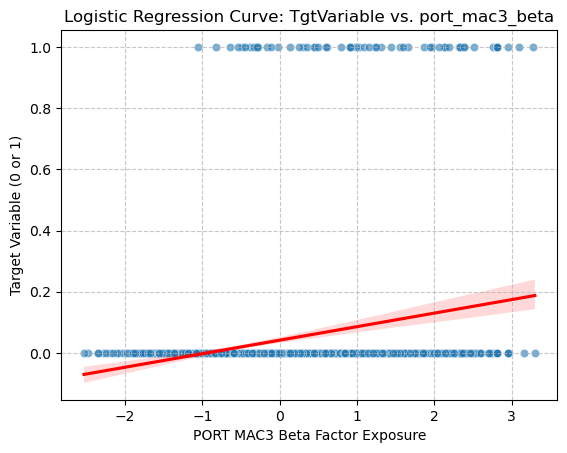

In [43]:
# Plot scatter plot and logistic regression curve for TgtVariable ~ port_mac3_beta
import seaborn as sns
import matplotlib.pyplot as plt
sns.scatterplot(data=df, x='port_mac3_beta', y='TgtVariable', alpha=0.6)
sns.regplot(data=df, x='port_mac3_beta', y='TgtVariable', logistic=False, color='red', scatter=False)
plt.title('Logistic Regression Curve: TgtVariable vs. port_mac3_beta')
plt.xlabel('PORT MAC3 Beta Factor Exposure')
plt.ylabel('Target Variable (0 or 1)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Why not Linear Regression?

If Linear Regression...

1.   There is no conception of probability of inclusion/exclusion
2.   Extremely good/confident predictions can be penalized.
3. Prediction can be nonsensical with probability outside of (0,1)


! ()[![image.png](https://i1.sndcdn.com/artworks-000561899583-nj2cst-t500x500.jpg)]

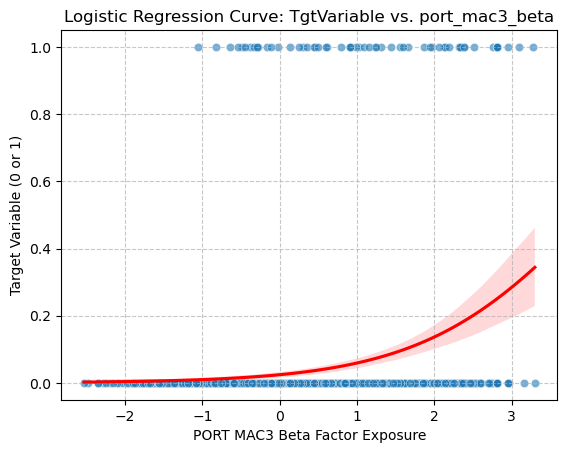

In [44]:
# Plot scatter plot and logistic regression curve for TgtVariable ~ port_mac3_beta
import seaborn as sns
import matplotlib.pyplot as plt
sns.scatterplot(data=df, x='port_mac3_beta', y='TgtVariable', alpha=0.6)
sns.regplot(data=df, x='port_mac3_beta', y='TgtVariable', logistic=True, color='red', scatter=False)
plt.title('Logistic Regression Curve: TgtVariable vs. port_mac3_beta')
plt.xlabel('PORT MAC3 Beta Factor Exposure')
plt.ylabel('Target Variable (0 or 1)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Sigmoid function

* Transforms predicted value gets into probability
* Very confident predictions will be capped at 0 or 1, so they are not penalized for their extremely large magnitudes.
* The expit function, also known as the logistic sigmoid function, is defined as expit(x) = 1/(1+exp(-x)). It is the inverse of the logit function.


Reference:
https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.expit.html#scipy.special.expit

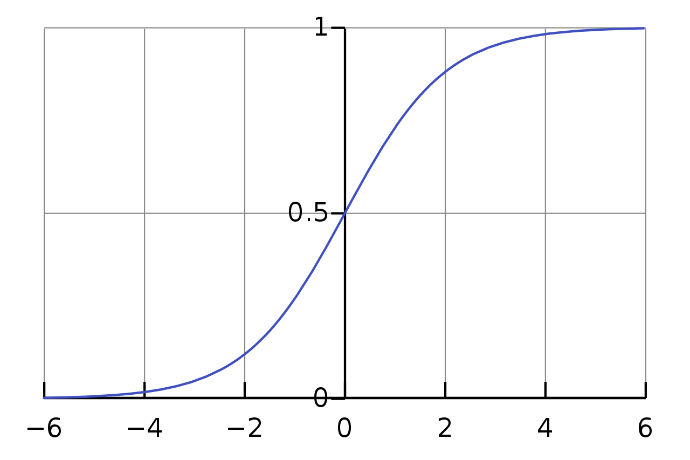

In [45]:
from scipy.special import expit
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(class_weight=None)
clf.fit(X=train_df[fnames], y=train_df['TgtVariable'])

# Now on the test set
ytest_pred = clf.predict(test_df[fnames])
ytest=test_df['TgtVariable'].values
print(classification_report(test_df['TgtVariable'], ytest_pred))
print(ytest_pred.sum())

              precision    recall  f1-score   support

           0       0.97      1.00      0.99       307
           1       0.83      0.38      0.53        13

    accuracy                           0.97       320
   macro avg       0.90      0.69      0.76       320
weighted avg       0.97      0.97      0.97       320

6


In [46]:
from scipy.special import expit
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(class_weight='balanced')
clf.fit(X=train_df[fnames], y=train_df['TgtVariable'])

# Now on the test set
ytest_pred = clf.predict(test_df[fnames])
ytest=test_df['TgtVariable'].values
print(classification_report(test_df['TgtVariable'], ytest_pred))
print(ytest_pred.sum())

              precision    recall  f1-score   support

           0       1.00      0.93      0.97       307
           1       0.39      1.00      0.57        13

    accuracy                           0.94       320
   macro avg       0.70      0.97      0.77       320
weighted avg       0.98      0.94      0.95       320

33


# ROC and AUC
Reference:


https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc

ROC curve (receiver operating characteristic curve) is a graph showing the performance of a classification model at all classification thresholds. This curve plots two parameters:

* True Positive Rate
* False Positive Rate

TPR=FPR line represents the performance of random guessing.
* (0,0) when always guess False.
* (1,1) when always guess True.
* In-between when guessing with probability p

AUC stands for "Area under the ROC Curve."
* AUC measures the area underneath the ROC curve
* i.e. integral from 0 to 1.
* aggregate measure of performance across all possible classification thresholds.
* A single score to summarize how good a predictor is.





In [47]:
from sklearn.metrics import roc_curve, auc

ytest_pred               = clf.predict(test_df[fnames])
probability               = clf.predict_proba(test_df[fnames])

print(ytest_pred[:10])
print(probability[:10])

[1 0 0 0 0 0 0 0 0 0]
[[2.22841958e-01 7.77158042e-01]
 [9.23928490e-01 7.60715098e-02]
 [9.99482236e-01 5.17764270e-04]
 [9.99329816e-01 6.70184276e-04]
 [9.99919208e-01 8.07918493e-05]
 [9.99298758e-01 7.01241917e-04]
 [9.97313837e-01 2.68616328e-03]
 [8.31830202e-01 1.68169798e-01]
 [9.99919134e-01 8.08660356e-05]
 [9.99909295e-01 9.07045924e-05]]


Text(0.5, 0, 'False Positive Rate')

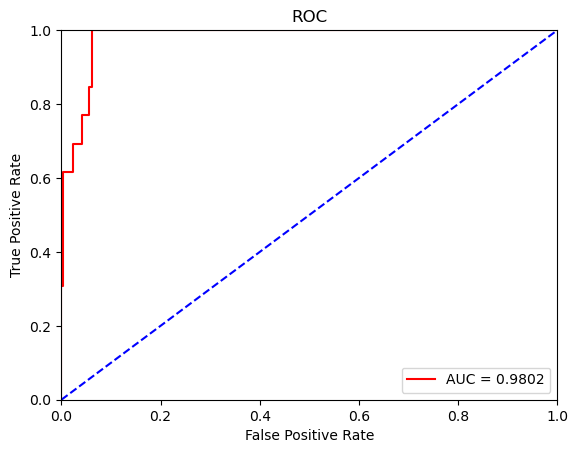

In [48]:

predicatbility               = probability[:,1]
false_positive_rate, true_positive_rate, threshold = roc_curve(test_df['TgtVariable'], predicatbility)
roc_auc             = auc(false_positive_rate, true_positive_rate)

plt.plot(false_positive_rate, true_positive_rate, 'red', label = 'AUC = %0.4f' % roc_auc)

plt.title('ROC')
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'b--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')

# Part 2: A neural network classifier in PyTorch

Last week ended on an idea: logistic regression is a weighted sum squashed by a sigmoid, and if you stack enough of those units together you get a neural network. Today we build that in PyTorch, the library behind most modern deep learning.

We do it in two steps. First, logistic regression itself, written as a one-neuron network, so you can see it is the same model. Then a network with two hidden layers. Along the way we answer three questions:

1. **Learning rate**: what happens when the step size is too small or too large?
2. **Adam**: why is it the default optimizer, and what does it do that plain gradient descent does not?
3. **Regularization**: does dropout help here, or not? What about weight decay and early stopping?

## Three splits, not two

A neural network has knobs: learning rate, number of epochs, dropout rate. If you turn those knobs while watching the test set, the test set stops being a test; you have fitted it by hand. So we carve a **validation set** out of the training set. We tune on validation and touch the test set once, at the very end.

* fit: 1,024 stocks, used to train the weights
* validation: 256 stocks, used to choose knobs and when to stop
* test: the same 320 stocks as above, untouched until the final table

Both splits are stratified, so all three keep the 4 percent AI rate.

In [49]:
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

torch.manual_seed(0)
fit_df, val_df = train_test_split(train_df, test_size=0.2, random_state=5, stratify=train_df['TgtVariable'])
print('fit:', len(fit_df), 'val:', len(val_df), 'test:', len(test_df))
print('AI stocks in each:', fit_df['TgtVariable'].sum(), val_df['TgtVariable'].sum(), test_df['TgtVariable'].sum())

fit: 1024 val: 256 test: 320
AI stocks in each: 42 10 13


## Scale the factors, using the fit split only

Neural networks train badly when one input is in the hundreds and another is near zero, so we standardize the 17 MAC3 factors to mean 0 and standard deviation 1. The sector dummies stay as 0 and 1: a 1 already means exactly one thing, and there is nothing to rescale. The scaler learns its means and standard deviations **from the fit split only**. If it saw the validation or test rows, information from those rows would leak into training, the same leakage idea as the momentum factor in Week 3.

PyTorch works on tensors, its version of a NumPy array. `pos_weight` is PyTorch's answer to `class_weight='balanced'`: every AI stock counts about 23 times in the loss, because there are about 23 non-AI stocks for each one.

In [50]:
def make_data(numeric_cols, dummy_cols):
    # the scaler learns from the fit split only
    scaler = StandardScaler().fit(fit_df[numeric_cols])
    def to_tensors(d):
        X = np.hstack([scaler.transform(d[numeric_cols]), d[dummy_cols].values])
        return torch.tensor(X, dtype=torch.float32), torch.tensor(d['TgtVariable'].values, dtype=torch.float32)
    data = {}
    for name, d in [('fit', fit_df), ('val', val_df), ('test', test_df)]:
        data['X_' + name], data['y_' + name] = to_tensors(d)
    data['pos_weight'] = (data['y_fit'] == 0).sum() / (data['y_fit'] == 1).sum()
    return data

data = make_data(mac3_names, sector_names)
print('X_fit shape:', tuple(data['X_fit'].shape), '| pos_weight:', round(data['pos_weight'].item(), 1))

X_fit shape: (1024, 27) | pos_weight: 23.4


## The model: logistic regression is one neuron

`nn.Linear(27, 1)` computes one weighted sum of the 27 features plus a bias. With a sigmoid on top, that **is** logistic regression. Give it hidden layers, each a `Linear` followed by a `ReLU`, and it becomes a neural network. `Dropout` is the regularizer we test later; at `p=0` it does nothing.

The model outputs the raw score, called a logit. We do not add a sigmoid layer, because the loss function applies it for us.

In [51]:
def make_model(hidden=(), dropout=0.0, n_in=None):
    layers, n_in = [], n_in or len(fnames)
    for h in hidden:
        layers += [nn.Linear(n_in, h), nn.ReLU(), nn.Dropout(dropout)]
        n_in = h
    layers.append(nn.Linear(n_in, 1))
    return nn.Sequential(*layers)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

print(make_model(), '\nweights:', n_params(make_model()))
print()
print(make_model((128, 128), dropout=0.3), '\nweights:', n_params(make_model((128, 128))))

Sequential(
  (0): Linear(in_features=27, out_features=1, bias=True)
) 
weights: 28

Sequential(
  (0): Linear(in_features=27, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=128, out_features=128, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=128, out_features=1, bias=True)
) 
weights: 20225


Logistic regression has 28 weights (27 features plus a bias). The two-hidden-layer network has about 20,000, and we have 1,024 training stocks, only 42 of them AI. Keep that ratio in mind.

## The training loop

Every PyTorch training loop repeats the same five lines:

1. **forward**: run a batch through the model to get scores
2. **loss**: compare scores to the truth. `BCEWithLogitsLoss` is binary cross-entropy that takes raw logits and applies the sigmoid inside, which is more numerically stable than doing it yourself
3. **zero_grad**: clear the gradients from the previous step
4. **backward**: compute the gradient of the loss with respect to every weight
5. **step**: the optimizer moves every weight a little against its gradient

One pass over all 1,024 stocks is an **epoch**; we feed them in mini-batches of 64. After each epoch we switch to `model.eval()`, which turns dropout off, and record the loss on the fit and validation sets. The function also remembers the weights from the epoch with the lowest validation loss; that is **early stopping**, and we use it later.

In [52]:
import copy

def train(model, optimizer, epochs=100, batch_size=64, seed=0, ds=None):
    ds = ds if ds is not None else data
    X_fit, y_fit, X_val, y_val = ds['X_fit'], ds['y_fit'], ds['X_val'], ds['y_val']
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=ds['pos_weight'])
    gen = torch.Generator().manual_seed(seed)
    history, best_val, best_state = [], float('inf'), None
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X_fit), generator=gen)
        for start in range(0, len(X_fit), batch_size):
            idx = order[start:start + batch_size]
            optimizer.zero_grad()
            loss = loss_fn(model(X_fit[idx]).squeeze(1), y_fit[idx])
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            fit_loss = loss_fn(model(X_fit).squeeze(1), y_fit).item()
            val_scores = model(X_val).squeeze(1)
            val_loss = loss_fn(val_scores, y_val).item()
            val_auc = roc_auc_score(y_val, val_scores)
        history.append({'epoch': epoch + 1, 'fit_loss': fit_loss, 'val_loss': val_loss, 'val_auc': val_auc})
        if val_loss < best_val:
            best_val, best_state = val_loss, copy.deepcopy(model.state_dict())
    return pd.DataFrame(history), best_state

## Question 1: the learning rate

The learning rate is the size of each step down the loss surface. Too small and the model crawls; too large and it overshoots the bottom and bounces. There is no formula for the right value, so we sweep it in factors of ten and look at the curves.

We use plain logistic regression (no hidden layer) so the only thing changing is the step size. Left panel: plain stochastic gradient descent (SGD). Right panel: Adam.

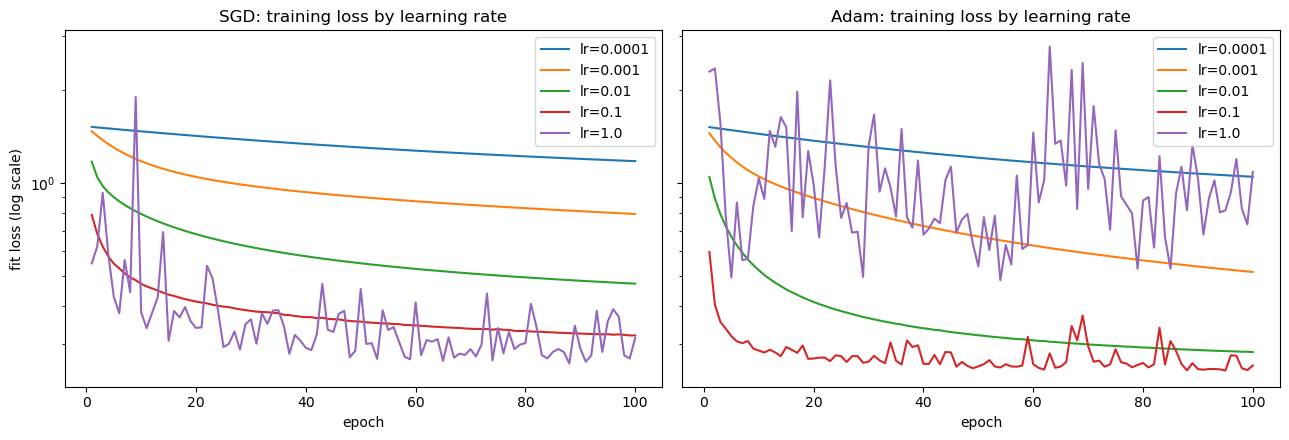

,optimizer,lr,loss_epoch_10,loss_epoch_100,worst_loss,val_auc
0,SGD,0.0001,1.470,1.177,1.520,0.751
1,SGD,0.0010,1.177,0.794,1.470,0.963
2,SGD,0.0100,0.793,0.472,1.173,0.978
3,SGD,0.1000,0.471,0.320,0.788,0.980
4,SGD,1.0000,0.381,0.315,1.900,0.974
5,Adam,0.0001,1.443,1.047,1.517,0.820
6,Adam,0.0010,1.050,0.515,1.448,0.975
7,Adam,0.0100,0.521,0.283,1.045,0.981
8,Adam,0.1000,0.286,0.256,0.598,0.978
9,Adam,1.0000,1.035,1.085,2.770,0.971


In [53]:
learning_rates = [0.0001, 0.001, 0.01, 0.1, 1.0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
rows = []
for ax, opt_name in zip(axes, ['SGD', 'Adam']):
    for lr in learning_rates:
        torch.manual_seed(0)
        model = make_model()
        opt_class = torch.optim.SGD if opt_name == 'SGD' else torch.optim.Adam
        hist, _ = train(model, opt_class(model.parameters(), lr=lr), epochs=100)
        ax.plot(hist['epoch'], hist['fit_loss'], label=f'lr={lr}')
        rows.append({'optimizer': opt_name, 'lr': lr, 'loss_epoch_10': hist['fit_loss'][9],
                     'loss_epoch_100': hist['fit_loss'].iloc[-1], 'worst_loss': hist['fit_loss'].max(),
                     'val_auc': hist['val_auc'].iloc[-1]})
    ax.set_title(f'{opt_name}: training loss by learning rate')
    ax.set_xlabel('epoch')
    ax.set_yscale('log')
    ax.legend()
axes[0].set_ylabel('fit loss (log scale)')
plt.tight_layout()
plt.show()
pd.DataFrame(rows).round({'loss_epoch_10': 3, 'loss_epoch_100': 3, 'worst_loss': 3, 'val_auc': 3})

**Reading the sweep.** At 0.0001 neither optimizer gets anywhere in 100 epochs: SGD's loss only falls from 1.52 to 1.18, and validation AUC is 0.75, because the model has barely started learning. At 0.001 it is still sliding downhill when we stop. From 0.01 to 0.1 both optimizers settle, between 0.26 and 0.47. At 1.0 the steps are too big: SGD's loss spikes as high as 1.9 along the way, and Adam spikes to 2.8 and finishes at 1.09, worse than it was at epoch 10 and almost four times its loss at 0.01.

Two lessons. Sweep the learning rate in factors of ten and look at the curve; a curve that jumps up is a step size that is too large. And notice that validation AUC sits between 0.96 and 0.98 for everything from 0.001 to 1.0, even where the loss is bouncing. AUC only cares about the ranking of the stocks, so it is forgiving. The loss is what tells you whether training is healthy.

## Question 2: what Adam does

Plain SGD moves every weight by the same rule: learning rate times gradient. Adam keeps two running averages for **each weight**:

* the average of its recent gradients (**momentum**): if the gradient keeps pointing the same way, keep rolling that way, and the noise from one mini-batch to the next cancels out
* the average of its recent squared gradients: a weight whose gradients are large or noisy gets smaller steps, and a weight whose gradients are small and steady gets larger ones

So each weight effectively gets its own learning rate, tuned on the fly. On a one-neuron model that barely matters. On a network with hidden layers, where weights in different layers see gradients of very different sizes, it matters a lot. Same network, same learning rate, two optimizers:

SGD: fit loss after 10 epochs 1.265, after 60 epochs 1.015


Adam: fit loss after 10 epochs 0.196, after 60 epochs 0.030


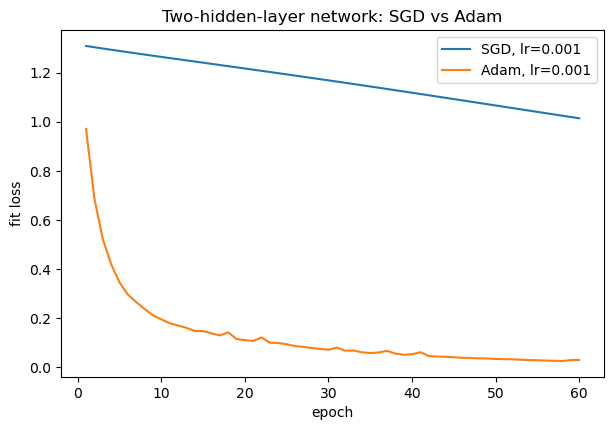

In [54]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for opt_name in ['SGD', 'Adam']:
    torch.manual_seed(0)
    model = make_model((128, 128))
    opt_class = torch.optim.SGD if opt_name == 'SGD' else torch.optim.Adam
    hist, _ = train(model, opt_class(model.parameters(), lr=0.001), epochs=60)
    ax.plot(hist['epoch'], hist['fit_loss'], label=f'{opt_name}, lr=0.001')
    print(f"{opt_name}: fit loss after 10 epochs {hist['fit_loss'][9]:.3f}, after 60 epochs {hist['fit_loss'].iloc[-1]:.3f}")
ax.set_title('Two-hidden-layer network: SGD vs Adam')
ax.set_xlabel('epoch')
ax.set_ylabel('fit loss')
ax.legend()
plt.show()

**Reading it.** After 10 epochs, SGD's loss is 1.27 and Adam's is 0.20. After 60 epochs, SGD is at 1.02 and Adam is at 0.03, more than thirty times lower. On the one-neuron model the two optimizers were close; with two hidden layers, Adam's per-weight step sizes make the difference. That is why Adam with a learning rate of 0.001 is the default in most of the field.

But look at Adam's 0.03. A loss that low on 1,024 stocks with 42 positives means the network is close to memorizing them. A faster optimizer gets you to the bottom of the training loss faster, and it gets you to overfitting faster too. That is the next question.

## Question 3: a bigger network overfits, so is regularization useful?

First, the problem regularization is meant to solve. Train the 19,000-weight network with Adam for 150 epochs, no regularization, and plot the loss on the fit set against the loss on the validation set.

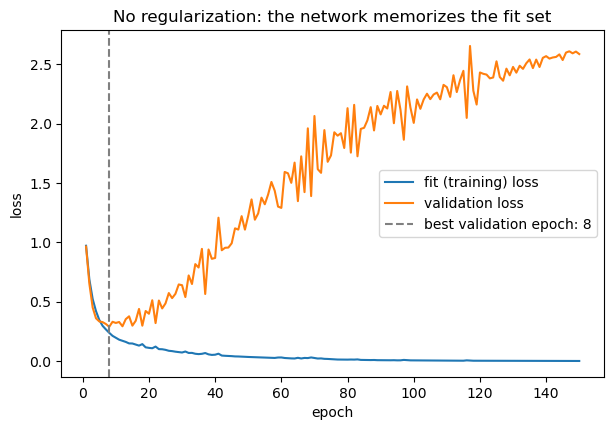

best validation loss 0.289 at epoch 8; at epoch 150: fit loss 0.0009, validation loss 2.586


In [55]:
torch.manual_seed(0)
model = make_model((128, 128))
hist, _ = train(model, torch.optim.Adam(model.parameters(), lr=0.001), epochs=150)

plt.figure(figsize=(7, 4.5))
plt.plot(hist['epoch'], hist['fit_loss'], label='fit (training) loss')
plt.plot(hist['epoch'], hist['val_loss'], label='validation loss')
best = hist.loc[hist['val_loss'].idxmin()]
plt.axvline(best['epoch'], color='grey', linestyle='--', label=f"best validation epoch: {int(best['epoch'])}")
plt.title('No regularization: the network memorizes the fit set')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()
print(f"best validation loss {best['val_loss']:.3f} at epoch {int(best['epoch'])}; "
      f"at epoch 150: fit loss {hist['fit_loss'].iloc[-1]:.4f}, validation loss {hist['val_loss'].iloc[-1]:.3f}")

**Reading it.** This is what overfitting looks like. The validation loss is lowest at epoch 8 (0.289). After that, the fit loss keeps falling to 0.0009, which means the network classifies every training stock perfectly, while the validation loss climbs to 2.6, nine times worse than its best. The network stopped learning what AI stocks look like and started memorizing which 42 stocks were on our list. With 20,225 weights and 1,024 stocks, it has room to memorize all of them.

## Three regularizers

* **Dropout**: during training, each step switches off a random fraction `p` of the hidden units. The network cannot lean on any single unit, so it has to spread what it learns across many of them. At evaluation time (`model.eval()`) every unit is back on.
* **Weight decay**: adds a penalty for large weights to the loss, the same L2 penalty that `LogisticRegression` applies through its `C` parameter. In PyTorch it is one argument to the optimizer.
* **Early stopping**: keep the weights from the epoch with the lowest validation loss instead of the last epoch. Our `train` function already does this.

One run can be lucky, so we train each setting with three different random seeds and average. For each run we report the validation loss at its best epoch and at the end, and the **test AUC of the early-stopped weights**. This is the first time any of these networks sees the test set.

This cell trains twelve networks; give it a few minutes on Colab's free CPU.

In [56]:
settings = [
    {'name': 'no regularization', 'dropout': 0.0, 'weight_decay': 0.0},
    {'name': 'dropout 0.3',       'dropout': 0.3, 'weight_decay': 0.0},
    {'name': 'dropout 0.5',       'dropout': 0.5, 'weight_decay': 0.0},
    {'name': 'weight decay 0.01', 'dropout': 0.0, 'weight_decay': 0.01},
]
results, curves = [], {}
for s in settings:
    for seed in range(3):
        torch.manual_seed(seed)
        model = make_model((128, 128), dropout=s['dropout'])
        opt = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=s['weight_decay'])
        hist, best_state = train(model, opt, epochs=150, seed=seed)
        if seed == 0:
            curves[s['name']] = hist['val_loss']
        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            test_auc = roc_auc_score(data['y_test'], model(data['X_test']).squeeze(1))
        results.append({'setting': s['name'], 'seed': seed,
                        'best_epoch': int(hist['val_loss'].idxmin()) + 1,
                        'best_val_loss': hist['val_loss'].min(),
                        'final_val_loss': hist['val_loss'].iloc[-1],
                        'test_auc_early_stopped': test_auc})

results = pd.DataFrame(results)
summary = results.groupby('setting', sort=False).agg(
    best_epoch=('best_epoch', 'mean'), best_val_loss=('best_val_loss', 'mean'),
    final_val_loss=('final_val_loss', 'mean'),
    test_auc_mean=('test_auc_early_stopped', 'mean'), test_auc_std=('test_auc_early_stopped', 'std'))
summary.round(3)

,best_epoch,best_val_loss,final_val_loss,test_auc_mean,test_auc_std
setting,,,,,
no regularization,6.667,0.290,3.007,0.974,0.003
dropout 0.3,10.000,0.276,2.577,0.972,0.006
dropout 0.5,15.333,0.269,2.084,0.974,0.005
weight decay 0.01,24.667,0.253,0.481,0.975,0.002


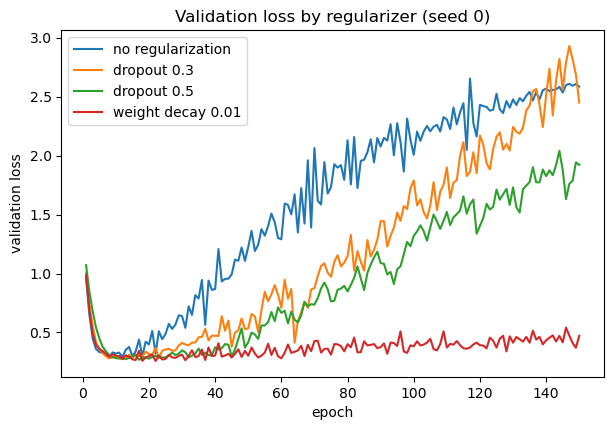

In [57]:
plt.figure(figsize=(7, 4.5))
for name, val_loss in curves.items():
    plt.plot(range(1, len(val_loss) + 1), val_loss, label=name)
plt.title('Validation loss by regularizer (seed 0)')
plt.xlabel('epoch')
plt.ylabel('validation loss')
plt.legend()
plt.show()

**Is regularization useful here? Yes and no, and the numbers say exactly where.**

* **It stops the damage from training too long.** With no regularization, the validation loss ends at 3.01. Dropout of 0.3 brings that to 2.58, dropout of 0.5 to 2.08, and weight decay holds it to 0.48. More dropout delays the overfitting (the best epoch moves from about 7 to 10 to 15), but over 150 epochs it still arrives. Weight decay is the one that holds it down.
* **It barely moves the result once you stop early.** The test AUC of the early-stopped weights is 0.974 with no regularization and 0.972 to 0.975 with it. The seed-to-seed spread is up to 0.006, and the test set has only 13 AI stocks, so those differences are noise. Early stopping was already doing the regularizing.

So on this data, dropout is not what makes or breaks the model. Early stopping matters most, weight decay is the cheapest insurance, and dropout earns its keep in big networks trained on big data, where you cannot afford to stop at epoch 7.

## The final table: does sector help?

Every model twice on the same 320 test stocks: once on the 17 MAC3 factors alone, once with the 10 sector dummies added. The scikit-learn models train on all 1,280 training stocks. The PyTorch models train on the 1,024 fit stocks and use the other 256 for early stopping: logistic regression with Adam at 0.01 for 100 epochs, and the 128x128 network with weight decay 0.01, averaged over three seeds. This cell takes a minute or two.

In [58]:
def torch_test_auc(ds, n_in, hidden=(), lr=0.01, weight_decay=0.0, epochs=100, seed=0):
    torch.manual_seed(seed)
    model = make_model(hidden, n_in=n_in)
    _, best_state = train(model, torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay),
                          epochs=epochs, seed=seed, ds=ds)
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        return roc_auc_score(ds['y_test'], model(ds['X_test']).squeeze(1))

feature_sets = {'MAC3 only': (mac3_names, []), 'MAC3 + sectors': (mac3_names, sector_names)}
rows = []
for set_name, (num_cols, dummy_cols) in feature_sets.items():
    cols = num_cols + dummy_cols
    ds = make_data(num_cols, dummy_cols)
    for label, sk_model in [('Gaussian Naive Bayes (sklearn)', GaussianNB()),
                            ('LDA (sklearn)', LinearDiscriminantAnalysis()),
                            ('Logistic regression, balanced (sklearn)', LogisticRegression(class_weight='balanced', max_iter=1000))]:
        sk_model.fit(train_df[cols], train_df['TgtVariable'])
        auc_value = roc_auc_score(test_df['TgtVariable'], sk_model.predict_proba(test_df[cols])[:, 1])
        rows.append({'model': label, 'features': set_name, 'test_auc': auc_value})
    rows.append({'model': 'Logistic regression, one neuron (PyTorch)', 'features': set_name,
                 'test_auc': torch_test_auc(ds, len(cols))})
    net_aucs = [torch_test_auc(ds, len(cols), hidden=(128, 128), lr=0.001, weight_decay=0.01, epochs=150, seed=seed)
                for seed in range(3)]
    rows.append({'model': 'Network 128x128, weight decay, early stopped (PyTorch, 3 seeds)', 'features': set_name,
                 'test_auc': np.mean(net_aucs)})

final = pd.DataFrame(rows).pivot(index='model', columns='features', values='test_auc')[['MAC3 only', 'MAC3 + sectors']]
final['change'] = final['MAC3 + sectors'] - final['MAC3 only']
final.sort_values('MAC3 + sectors', ascending=False).round(3)

features,MAC3 only,MAC3 + sectors,change
model,,,
"Logistic regression, one neuron (PyTorch)",0.954,0.981,0.026
"Logistic regression, balanced (sklearn)",0.954,0.980,0.026
LDA (sklearn),0.959,0.979,0.020
"Network 128x128, weight decay, early stopped (PyTorch, 3 seeds)",0.947,0.975,0.028
Gaussian Naive Bayes (sklearn),0.921,0.893,-0.028


**Reading the table.** Sector adds 0.02 to 0.03 of AUC to four of the five models. Logistic regression goes from 0.954 to 0.98, the same in PyTorch and scikit-learn, which confirms they are the same model. LDA goes from 0.959 to 0.979, and the network from 0.947 to 0.975. Gaussian Naive Bayes is the exception: it falls from 0.921 to 0.893, because 0/1 columns violate its bell-curve assumption.

Two lessons. The biggest gain today came from a better feature, not a bigger model: knowing that "AI stock" is mostly a technology label was worth more than 20,000 weights, a tuned learning rate and dropout combined. And the network still does not beat logistic regression; at the top of the table, 0.975 to 0.981 is within the noise. A network earns its weights when there is a lot of data and the signal is tangled: pixels, words, audio. Here we have 42 positive examples and 27 clean inputs. Always fit the simple model first; the complex one has to beat it on the test set to earn its place.

## Reflection questions

1. Why does the validation set exist? What exactly goes wrong if you choose the dropout rate by looking at test AUC?
2. The network has about 20,000 weights and 42 AI stocks to learn from. Predict what would happen to the gap between the network and logistic regression if you had 100 times as many labeled stocks. Why?
3. Dropout delayed overfitting but did not stop it, and weight decay held it down. Explain the difference in plain words.
4. The learning-rate sweep found a range of values that work. Which would you pick, and what would you look at to decide?
5. Name a classification problem where you would expect a neural network to beat logistic regression easily, and say what about the data makes the difference.
6. Why give each sector its own 0/1 column instead of numbering the sectors 1 to 11? And why does keeping all 11 columns cause trouble for LDA?
7. Adding sector raised logistic regression's test AUC from 0.954 to 0.98 and lowered Gaussian Naive Bayes from 0.92 to 0.89. Explain both, and say what you would change so Naive Bayes can use the sector columns properly.